# Лабораторная работа №1: регрессия

**Задача:** по химическому составу вина предсказать его оценку `quality` (от 3 до 9).
**Данные:** Wine Quality (UCI), общий датасет — красное и белое вино вместе.
**Метрика:** RMSE (основная) и MAE, требование — RMSE < 0.70 у всех моделей.

## 0. Импорты

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler, SplineTransformer, PolynomialFeatures
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error

RANDOM_STATE = 42          # фиксируем случайность, чтобы результат воспроизводился
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)

## 1. Загрузка данных

Файлы `winequality-red.csv` и `winequality-white.csv` скачаны с
https://archive.ics.uci.edu/dataset/186/wine+quality и лежат в папке `data/`.
Склеиваем их в одну таблицу и добавляем признак `is_red` (1 — красное, 0 — белое).

In [2]:
red = pd.read_csv("data/winequality-red.csv", sep=";")
white = pd.read_csv("data/winequality-white.csv", sep=";")
red["is_red"] = 1
white["is_red"] = 0
df = pd.concat([red, white], ignore_index=True)

print(df.shape)
df.head()

(6497, 13)


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,is_red
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,1
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,1
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,1
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,1
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,1


## 2. Первичный анализ данных

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 6497 entries, 0 to 6496
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         6497 non-null   float64
 1   volatile acidity      6497 non-null   float64
 2   citric acid           6497 non-null   float64
 3   residual sugar        6497 non-null   float64
 4   chlorides             6497 non-null   float64
 5   free sulfur dioxide   6497 non-null   float64
 6   total sulfur dioxide  6497 non-null   float64
 7   density               6497 non-null   float64
 8   pH                    6497 non-null   float64
 9   sulphates             6497 non-null   float64
 10  alcohol               6497 non-null   float64
 11  quality               6497 non-null   int64  
 12  is_red                6497 non-null   int64  
dtypes: float64(11), int64(2)
memory usage: 660.0 KB


In [4]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
fixed acidity,6497.0,7.215307,1.296434,3.80000,6.40000,7.00000,7.70000,15.90000
volatile acidity,6497.0,0.339666,0.164636,0.08000,0.23000,0.29000,0.40000,1.58000
citric acid,6497.0,0.318633,0.145318,0.00000,0.25000,0.31000,0.39000,1.66000
residual sugar,6497.0,5.443235,4.757804,0.60000,1.80000,3.00000,8.10000,65.80000
chlorides,6497.0,0.056034,0.035034,0.00900,0.03800,0.04700,0.06500,0.61100
free sulfur dioxide,6497.0,30.525319,17.749400,1.00000,17.00000,29.00000,41.00000,289.00000
total sulfur dioxide,6497.0,115.744574,56.521855,6.00000,77.00000,118.00000,156.00000,440.00000
density,6497.0,0.994697,0.002999,0.98711,0.99234,0.99489,0.99699,1.03898
pH,6497.0,3.218501,0.160787,2.72000,3.11000,3.21000,3.32000,4.01000
sulphates,6497.0,0.531268,0.148806,0.22000,0.43000,0.51000,0.60000,2.00000


In [5]:
print("Пропусков:", df.isna().sum().sum())
print("Полных дубликатов строк:", df.duplicated().sum())

Пропусков: 0
Полных дубликатов строк: 1177


**Вывод.** Все признаки числовые, пропусков нет, поэтому ничего заполнять не нужно.
Признаки измеряются в очень разных единицах. Для линейной регрессии их нужно привести к одному масштабу, иначе её коэффициенты нельзя сравнивать между собой.
У некоторых признаков (сахар, диоксид серы, хлориды) есть выбросы — отдельные вина с очень большими значениями.

В данных много полностью одинаковых строк. Это может завысить оценку модели так как они могут попасть в train и test, модель на test «узнает» вино, которое уже видела в train. Насколько это влияет на результат, проверим в разделе 8.

### Целевая переменная

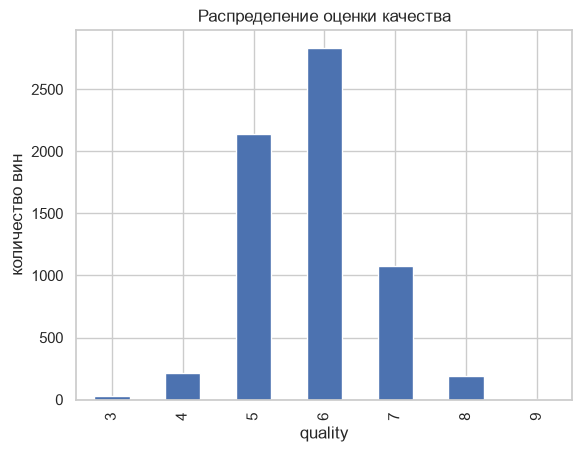

quality
3      30
4     216
5    2138
6    2836
7    1079
8     193
9       5
Name: count, dtype: int64

In [6]:
ax = df["quality"].value_counts().sort_index().plot(kind="bar")
ax.set_xlabel("quality"); ax.set_ylabel("количество вин")
plt.title("Распределение оценки качества")
plt.show()
df["quality"].value_counts().sort_index()

**Вывод.** Оценки сильно несбалансированы: 77% вин получили 5 или 6, а оценок 3 и 9 всего 30 и 5.
Значит, модель в основном будет учиться на средних винах и, скорее всего, плохо предсказывать очень плохие
и очень хорошие вина — для них мало примеров.

### Связь признаков с качеством

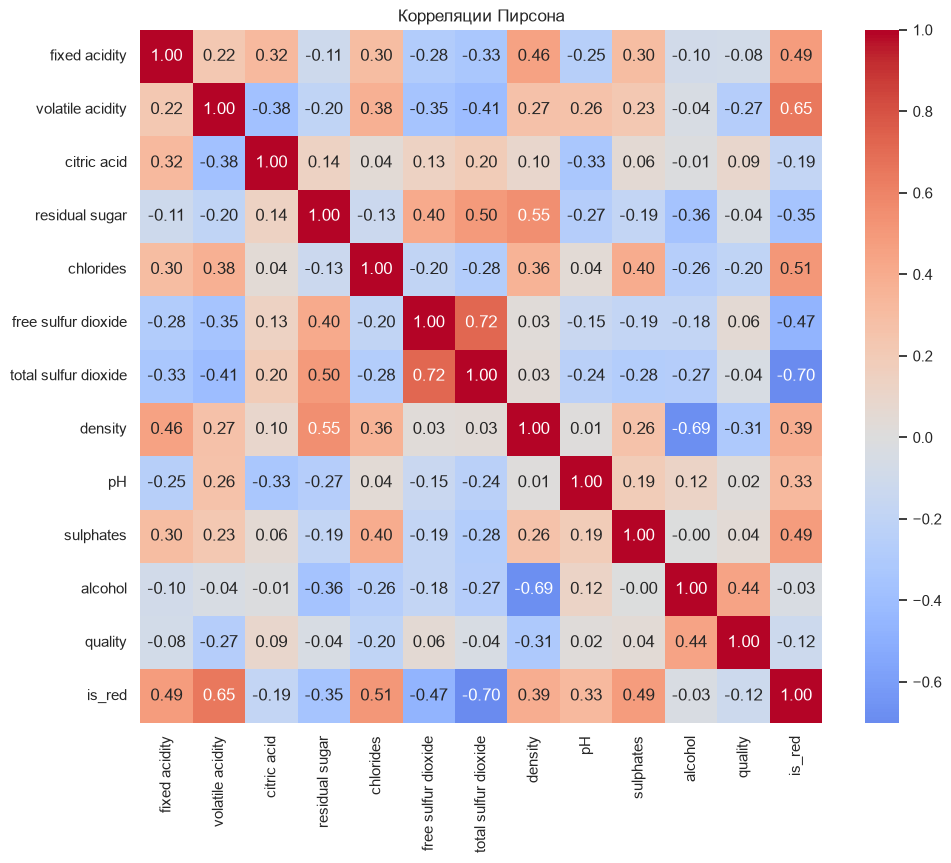

density                -0.305858
volatile acidity       -0.265699
chlorides              -0.200666
is_red                 -0.119323
fixed acidity          -0.076743
total sulfur dioxide   -0.041385
residual sugar         -0.036980
pH                      0.019506
sulphates               0.038485
free sulfur dioxide     0.055463
citric acid             0.085532
alcohol                 0.444319
Name: quality, dtype: float64

In [7]:
corr = df.corr()
plt.figure(figsize=(11, 9))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Корреляции Пирсона")
plt.show()

corr["quality"].drop("quality").sort_values()

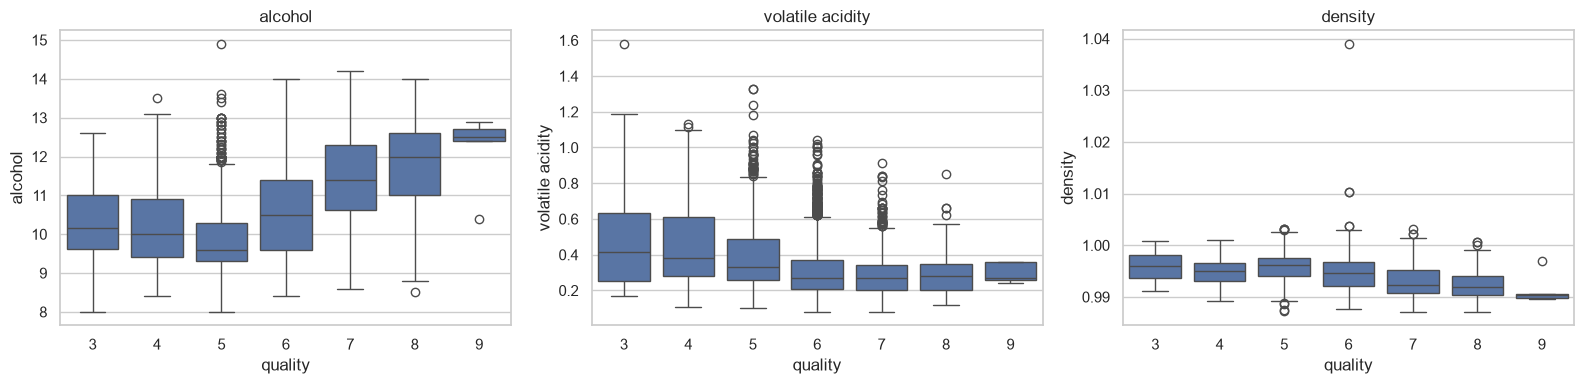

In [8]:
fig, axs = plt.subplots(1, 3, figsize=(16, 4))
for ax, col in zip(axs, ["alcohol", "volatile acidity", "density"]):
    sns.boxplot(data=df, x="quality", y=col, ax=ax)
    ax.set_title(col)
plt.tight_layout(); plt.show()

**Вывод.**
- Сильнее всего с качеством связан алкоголь: чем крепче вино, тем выше оценка. Это главный кандидат в важные признаки.
- Летучая кислотность, плотность и хлориды связаны с качеством обратно: чем их больше, тем оценка в среднем ниже.
- У остальных признаков связь с качеством почти нулевая, но это проверка только прямой зависимости: деревья могут найти в них пользу.
- Некоторые признаки дублируют друг друга (например, алкоголь и плотность), поэтому коэффициенты линейной модели для них могут быть странными.
- Ящики соседних оценок сильно перекрываются: по одному признаку хорошее вино от среднего не отличить, нужна модель, которая смотрит на все признаки сразу.

## 3. Разбиение на train и test

In [9]:
X = df.drop(columns=["quality"])   # признаки (целевую переменную убираем!)
y = df["quality"]                  # целевая переменная

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)
print("train:", X_train.shape, " test:", X_test.shape)

train: (5197, 12)  test: (1300, 12)


**Пояснение.**
- 80% данных (5197 вин) — на обучение, 20% (1300 вин) — на проверку. Этого хватает и для обучения,
  и для устойчивой оценки качества.
- `stratify=y` сохраняет одинаковые доли оценок в train и test. Без этого редкие оценки (3, 8, 9)
  могли бы почти не попасть в одну из частей.
- `random_state` фиксирует разбиение, поэтому результат повторяется при каждом запуске.

## 4. Метрики и baseline

In [10]:
results = {}   # сюда складываем метрики всех моделей

def evaluate(name, y_true, y_pred):
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mae = mean_absolute_error(y_true, y_pred)
    results[name] = {"RMSE": rmse, "MAE": mae}
    print(f"{name:45s} RMSE = {rmse:.4f}   MAE = {mae:.4f}")

In [11]:
# Baseline: всем винам предсказываем среднее значение quality по train
const = y_train.mean()
print("Константа:", round(const, 3))
evaluate("Baseline (mean)", y_test, np.full(len(y_test), const))

# Для сравнения — медиана (в итоговую таблицу не идёт)
med = np.full(len(y_test), y_train.median())
print(f"Медиана: RMSE = {np.sqrt(mean_squared_error(y_test, med)):.4f}   MAE = {mean_absolute_error(y_test, med):.4f}")

Константа: 5.818
Baseline (mean)                               RMSE = 0.8738   MAE = 0.6861
Медиана: RMSE = 0.8923   MAE = 0.6377


**Вывод.**
- Baseline ставит всем винам среднюю оценку (5.82) и ошибается на RMSE 0.874. Модели должны быть заметно лучше, иначе они ничему не научились.
- Берём среднее, а не медиану: для RMSE среднее даёт меньшую ошибку.
- **MAE** — на сколько баллов в среднем ошибается модель.
- **RMSE** — тоже ошибка в баллах, но крупные промахи в ней весят сильнее, потому что ошибки возводятся в квадрат.
- Поэтому RMSE всегда не меньше MAE, и чем больше разница между ними, тем больше у модели крупных промахов.

## 5. Линейная регрессия

In [12]:
lin = Pipeline([
    ("scaler", StandardScaler()),       # стандартизация: среднее 0, разброс 1 (обучается только на train)
    ("model", LinearRegression()),
])
lin.fit(X_train, y_train)
evaluate("Linear Regression (простая)", y_test, lin.predict(X_test))

Linear Regression (простая)                   RMSE = 0.7280   MAE = 0.5678


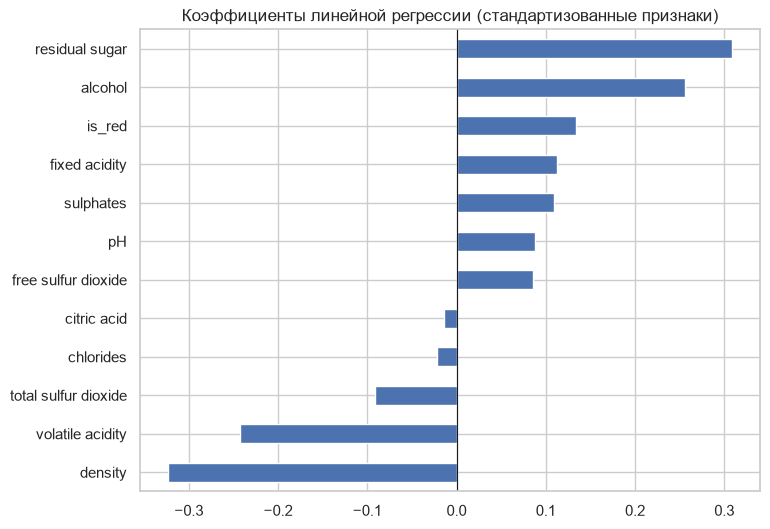

density                -0.322959
volatile acidity       -0.242319
total sulfur dioxide   -0.090906
chlorides              -0.021916
citric acid            -0.013599
free sulfur dioxide     0.086140
pH                      0.088102
sulphates               0.109287
fixed acidity           0.112144
is_red                  0.133536
alcohol                 0.255823
residual sugar          0.308646
dtype: float64

In [13]:
coefs = pd.Series(lin.named_steps["model"].coef_, index=X.columns).sort_values()
coefs.plot(kind="barh", figsize=(8, 6))
plt.title("Коэффициенты линейной регрессии (стандартизованные признаки)")
plt.axvline(0, color="k", lw=0.8)
plt.show()
coefs

In [14]:
# Для сравнения: та же модель без масштабирования
lin_raw = LinearRegression().fit(X_train, y_train)
print(f"RMSE без масштабирования: {np.sqrt(mean_squared_error(y_test, lin_raw.predict(X_test))):.4f}")
pd.Series(lin_raw.coef_, index=X.columns).round(3)

RMSE без масштабирования: 0.7280


fixed acidity             0.087
volatile acidity         -1.462
citric acid              -0.093
residual sugar            0.065
chlorides                -0.635
free sulfur dioxide       0.005
total sulfur dioxide     -0.002
density                -107.254
pH                        0.548
sulphates                 0.745
alcohol                   0.215
is_red                    0.309
dtype: float64

**Вывод.**
- Простая линейная регрессия лучше baseline, но не проходит порог 0.70: она умеет описывать только прямые зависимости, а связь качества с составом вина сложнее.
- Масштабирование не меняет качество, но без него коэффициенты нельзя сравнивать: у плотности получается огромный вес только потому, что она измеряется в маленьких числах.
- После масштабирования сильнее всего на предсказание влияют плотность, сахар, алкоголь и летучая кислотность.
- Сахар получил большой вес, хотя напрямую с качеством почти не связан. Это потому, что плотность, сахар и алкоголь связаны между собой, и модель распределяет влияние между ними. Поэтому отдельные коэффициенты нельзя читать буквально.

### 5b. Линейная регрессия с нелинейными признаками

Чтобы пройти порог, оставляем модель линейной, но строим для неё более богатые признаки:
- **сплайны** — каждый признак разбивается на участки со своим наклоном, зависимость может изгибаться;
- **попарные произведения** признаков — эффект одного признака может зависеть от другого;
- признаков становится несколько тысяч, поэтому берём **Ridge** (линейная регрессия со штрафом за большие веса),
  силу штрафа `alpha` подбираем кросс-валидацией на train.

In [15]:
lin_rich = Pipeline([
    ("scaler", StandardScaler()),
    ("splines", SplineTransformer(n_knots=10)),
    ("interactions", PolynomialFeatures(degree=2, interaction_only=True, include_bias=False)),
    ("model", Ridge()),
])
search_lin = GridSearchCV(
    lin_rich, {"model__alpha": [3, 10, 30]},
    cv=5, scoring="neg_root_mean_squared_error", n_jobs=-1,
)
search_lin.fit(X_train, y_train)
print("Лучший alpha:", search_lin.best_params_)
print("RMSE на кросс-валидации:", round(-search_lin.best_score_, 4))

lin_best = search_lin.best_estimator_
evaluate("Linear Regression (сплайны + взаимодействия)", y_test, lin_best.predict(X_test))

Лучший alpha: {'model__alpha': 10}
RMSE на кросс-валидации: 0.6816
Linear Regression (сплайны + взаимодействия)  RMSE = 0.6735   MAE = 0.5237


**Вывод.** Когда мы разрешили модели изгибать зависимости и учитывать сочетания признаков, ошибка упала с 0.728 до 0.674, и порог 0.70 пройден. Значит, качество вина зависит от состава не по прямой, и признаки влияют друг на друга. Модель при этом осталась линейной регрессией.

## 6. Random Forest

In [16]:
rf = RandomForestRegressor(n_estimators=500, random_state=RANDOM_STATE, n_jobs=-1)
rf.fit(X_train, y_train)
evaluate("Random Forest", y_test, rf.predict(X_test))

Random Forest                                 RMSE = 0.6054   MAE = 0.4301


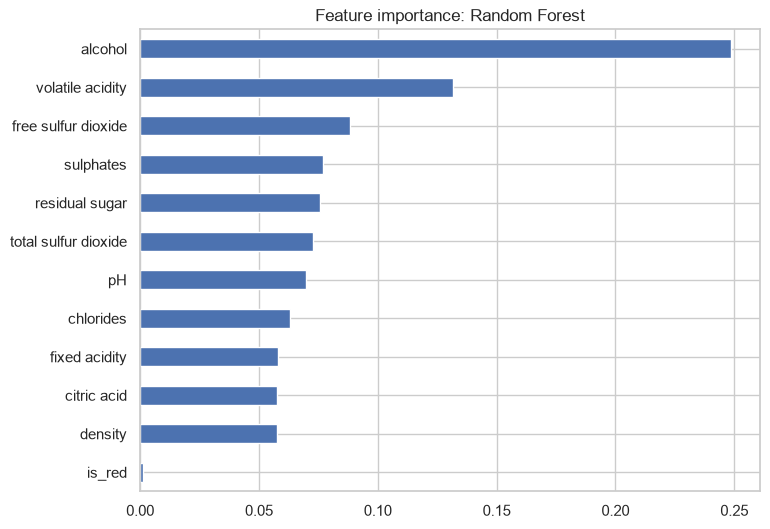

alcohol                 0.248
volatile acidity        0.131
free sulfur dioxide     0.088
sulphates               0.077
residual sugar          0.075
total sulfur dioxide    0.073
pH                      0.070
chlorides               0.063
fixed acidity           0.058
citric acid             0.058
density                 0.057
is_red                  0.001
dtype: float64

In [17]:
rf_imp = pd.Series(rf.feature_importances_, index=X.columns).sort_values()
rf_imp.plot(kind="barh", figsize=(8, 6))
plt.title("Feature importance: Random Forest")
plt.show()
rf_imp.sort_values(ascending=False).round(3)

**Вывод.** Random Forest ошибается заметно меньше линейных моделей.
- Самые важные признаки для леса — алкоголь и летучая кислотность. Это совпадает с тем, что мы увидели в анализе данных.
- Лес также пользуется признаками, у которых почти нет прямой связи с качеством (диоксид серы, сульфаты, сахар): деревья умеют находить в них более сложные зависимости.
- Плотность, которая в линейной модели была на первом месте, для леса почти не важна: лесу хватает алкоголя и сахара, от которых плотность и так зависит.
- Признак «красное/белое» лес почти не использует: тип вина и так видно по другим признакам.

## 7. Gradient Boosting

In [18]:
gb_default = GradientBoostingRegressor(random_state=RANDOM_STATE)
gb_default.fit(X_train, y_train)
evaluate("Gradient Boosting (default)", y_test, gb_default.predict(X_test))

Gradient Boosting (default)                   RMSE = 0.6762   MAE = 0.5318


In [19]:
param_grid = {
    "n_estimators": [300, 600],
    "learning_rate": [0.05, 0.1],
    "max_depth": [3, 5, 7],
}
search = GridSearchCV(
    GradientBoostingRegressor(subsample=0.8, random_state=RANDOM_STATE),
    param_grid, cv=5, scoring="neg_root_mean_squared_error", n_jobs=-1,
)
search.fit(X_train, y_train)          # подбор только на train
print("Лучшие параметры:", search.best_params_)
print("RMSE на кросс-валидации:", round(-search.best_score_, 4))

gb = search.best_estimator_
evaluate("Gradient Boosting (tuned)", y_test, gb.predict(X_test))

Лучшие параметры: {'learning_rate': 0.05, 'max_depth': 7, 'n_estimators': 600}
RMSE на кросс-валидации: 0.6243
Gradient Boosting (tuned)                     RMSE = 0.5982   MAE = 0.4103


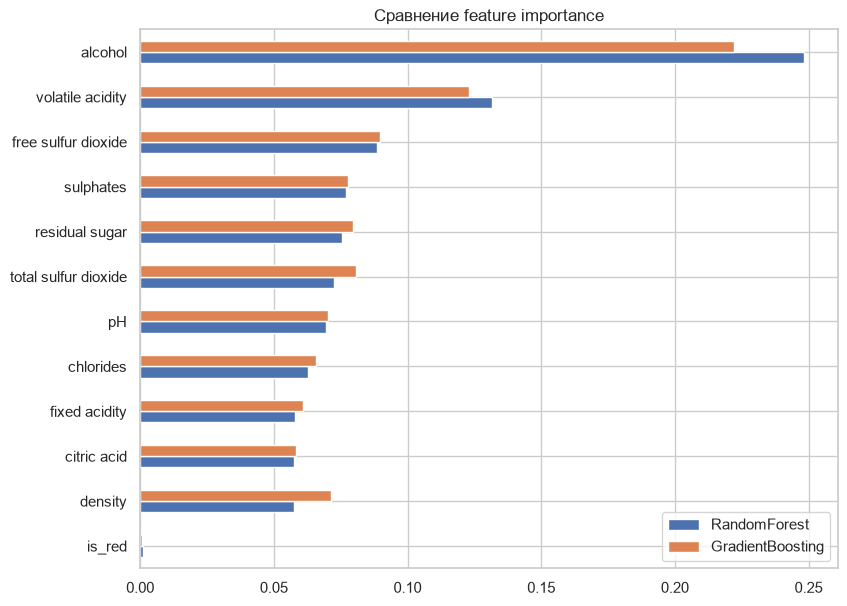

,RandomForest,GradientBoosting
alcohol,0.248,0.222
volatile acidity,0.131,0.123
free sulfur dioxide,0.088,0.090
sulphates,0.077,0.078
residual sugar,0.075,0.079
total sulfur dioxide,0.073,0.081
pH,0.070,0.070
chlorides,0.063,0.066
fixed acidity,0.058,0.061
citric acid,0.058,0.058


In [20]:
gb_imp = pd.Series(gb.feature_importances_, index=X.columns)
imp = pd.DataFrame({"RandomForest": rf_imp, "GradientBoosting": gb_imp}).sort_values("RandomForest")
imp.plot(kind="barh", figsize=(9, 7))
plt.title("Сравнение feature importance")
plt.show()
imp.sort_values("RandomForest", ascending=False).round(3)

**Вывод.**
- С настройками по умолчанию бустинг слабее леса: деревьев мало и они мелкие, поэтому сложные зависимости модель не улавливает. После подбора (больше деревьев, глубже, маленький шаг) бустинг стал лучшей моделью.
- Важные признаки у бустинга те же, что у леса: на первом месте алкоголь, на втором летучая кислотность, остальные примерно одинаково полезны. Две разные модели пришли к одному выводу, значит, эти признаки действительно главные.

**Можно ли по важности признака сказать, что он — причина качества?** Нет. Важность показывает только, что модель пользуется признаком для предсказания. Например, и высокий алкоголь, и высокая оценка могут быть следствием спелого винограда. Кроме того, на качество влияют вещи, которых нет в данных: сорт винограда, выдержка, вкус эксперта.

## 8. Итоговое сравнение

In [21]:
res = pd.DataFrame(results).T.sort_values("RMSE")
res["лучше baseline"] = res["RMSE"] < results["Baseline (mean)"]["RMSE"]
res["RMSE < 0.70"] = res["RMSE"] < 0.70
res.round(4)

,RMSE,MAE,лучше baseline,RMSE < 0.70
Gradient Boosting (tuned),0.5982,0.4103,True,True
Random Forest,0.6054,0.4301,True,True
Linear Regression (сплайны + взаимодействия),0.6735,0.5237,True,True
Gradient Boosting (default),0.6762,0.5318,True,True
Linear Regression (простая),0.7280,0.5678,True,False
Baseline (mean),0.8738,0.6861,False,False


In [22]:
# Насколько модели подстроились под train: ошибка на train против ошибки на test
for name, m in [("Linear (простая)", lin), ("Random Forest", rf), ("Gradient Boosting (tuned)", gb)]:
    tr = np.sqrt(mean_squared_error(y_train, m.predict(X_train)))
    te = np.sqrt(mean_squared_error(y_test, m.predict(X_test)))
    print(f"{name:28s} train RMSE = {tr:.3f}   test RMSE = {te:.3f}")

Linear (простая)             train RMSE = 0.734   test RMSE = 0.728
Random Forest                train RMSE = 0.223   test RMSE = 0.605
Gradient Boosting (tuned)    train RMSE = 0.109   test RMSE = 0.598


**Вывод.**
- Все модели лучше baseline. Порог 0.70 не прошла только простая линейная регрессия.
- Модели на деревьях (лес и бустинг) работают заметно лучше линейных: деревья сами находят правила вроде «много алкоголя И мало кислотности», а линейной модели такие сочетания приходится строить вручную.
- Лес и подобранный бустинг дали почти одинаковый результат. Лес хорош сразу, без настройки, а бустинг становится лучшим только после подбора параметров.
- На обучающих винах деревья ошибаются гораздо меньше, чем на тестовых: часть обучающих данных они просто запомнили. На тесте качество всё равно хорошее, но это признак того, что модели сложные и склонны к переобучению.

### Проверка: влияние дубликатов

In [23]:
# Сколько вин из теста имеют точную копию в train
train_rows = X_train.assign(quality=y_train).drop_duplicates()
copies = X_test.assign(quality=y_test).merge(train_rows, how="inner")
print("Вин в test с точной копией в train:", len(copies), "из", len(X_test))

# Тот же Random Forest на данных без дубликатов
df_nodup = df.drop_duplicates()
Xn, yn = df_nodup.drop(columns=["quality"]), df_nodup["quality"]
Xn_tr, Xn_te, yn_tr, yn_te = train_test_split(Xn, yn, test_size=0.2, random_state=RANDOM_STATE, stratify=yn)
rf_nodup = RandomForestRegressor(n_estimators=500, random_state=RANDOM_STATE, n_jobs=-1).fit(Xn_tr, yn_tr)
print(f"Random Forest без дубликатов: RMSE = {np.sqrt(mean_squared_error(yn_te, rf_nodup.predict(Xn_te))):.4f}")

Вин в test с точной копией в train: 357 из 1300
Random Forest без дубликатов: RMSE = 0.6850


**Вывод.** Примерно у четверти вин из тестовой выборки есть точная копия в обучающей. Модель уже видела такие вина при обучении, поэтому на тесте она их легко «угадывает», и её результат выглядит лучше, чем есть на самом деле. Если убрать дубликаты, ошибка Random Forest вырастает с 0.605 до 0.685, но порог 0.70 он всё равно проходит. Значит, на действительно новых винах модель будет ошибаться немного сильнее, чем показывает тест.

## 9. Анализ ошибок лучшей модели

Лучшая модель: Gradient Boosting (tuned)
Доля ошибок меньше 0.5 балла: 0.686
Доля ошибок меньше 1 балла:   0.898


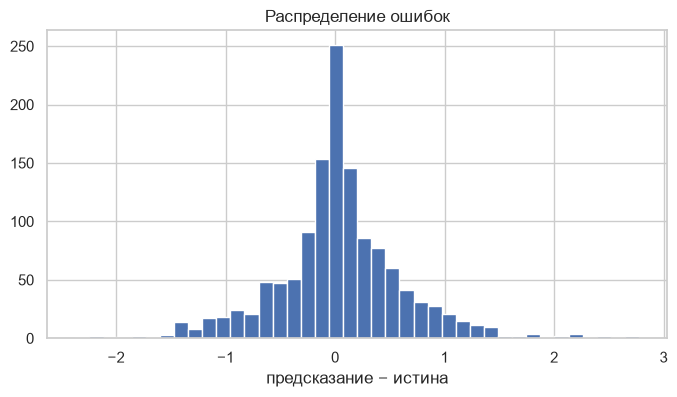

In [24]:
best_name = res.index[0]
models = {"Random Forest": rf, "Gradient Boosting (tuned)": gb,
          "Gradient Boosting (default)": gb_default,
          "Linear Regression (простая)": lin,
          "Linear Regression (сплайны + взаимодействия)": lin_best}
best_model = models[best_name]
print("Лучшая модель:", best_name)

errors = pd.DataFrame({"true": y_test, "pred": best_model.predict(X_test)})
errors["error"] = errors["pred"] - errors["true"]     # > 0 — завысили, < 0 — занизили
errors["abs_error"] = errors["error"].abs()

print("Доля ошибок меньше 0.5 балла:", round((errors["abs_error"] < 0.5).mean(), 3))
print("Доля ошибок меньше 1 балла:  ", round((errors["abs_error"] < 1).mean(), 3))

errors["error"].hist(bins=40, figsize=(8, 4))
plt.xlabel("предсказание − истина"); plt.title("Распределение ошибок")
plt.show()

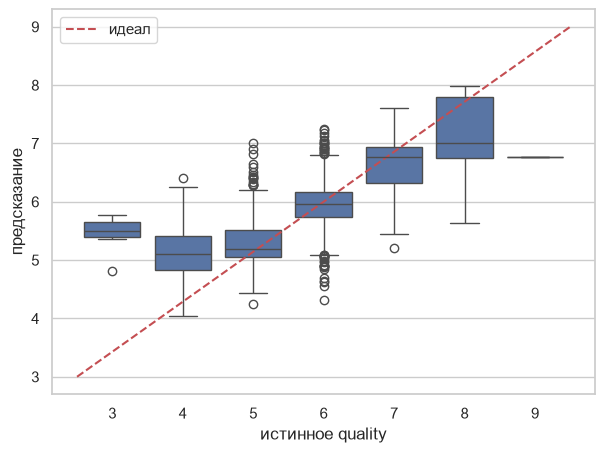

In [25]:
plt.figure(figsize=(7, 5))
sns.boxplot(data=errors, x="true", y="pred")
plt.plot([-0.5, 6.5], [3, 9], "r--", label="идеал")   # категории 3..9 стоят на позициях 0..6
plt.xlabel("истинное quality"); plt.ylabel("предсказание"); plt.legend()
plt.show()

In [26]:
by_q = errors.groupby("true").apply(
    lambda g: pd.Series({"n": len(g),
                         "RMSE": np.sqrt((g["error"] ** 2).mean()),
                         "средняя ошибка": g["error"].mean()})
)
by_q.round(3)

,n,RMSE,средняя ошибка
true,,,
3,6.0,2.462,2.442
4,43.0,1.312,1.185
5,428.0,0.517,0.317
6,567.0,0.443,-0.046
7,216.0,0.604,-0.397
8,39.0,1.078,-0.858
9,1.0,2.228,-2.228


In [27]:
worst = errors.sort_values("abs_error", ascending=False).head(10)
worst.join(X_test).round(3)

,true,pred,error,abs_error,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,is_red
1374,3,5.776,2.776,2.776,6.8,0.815,0.00,1.20,0.267,16.0,29.0,0.995,3.32,0.51,9.8,1
1850,3,5.687,2.687,2.687,8.5,0.260,0.21,16.20,0.074,41.0,197.0,0.998,3.02,0.50,9.8,0
3287,3,5.547,2.547,2.547,6.7,0.250,0.26,1.55,0.041,118.5,216.0,0.995,3.55,0.63,9.4,0
2339,3,5.468,2.468,2.468,6.9,0.390,0.40,4.60,0.022,5.0,19.0,0.992,3.31,0.37,12.6,0
6107,4,6.415,2.415,2.415,5.8,0.260,0.30,2.60,0.034,75.0,129.0,0.990,3.20,0.38,11.5,0
3005,8,5.629,-2.371,2.371,8.2,0.220,0.36,6.80,0.034,12.0,90.0,0.994,3.01,0.38,10.5,0
1469,3,5.364,2.364,2.364,7.3,0.980,0.05,2.10,0.061,20.0,49.0,0.997,3.31,0.55,9.7,1
5369,4,6.255,2.255,2.255,7.4,0.270,0.31,2.40,0.014,15.0,143.0,0.991,3.03,0.65,12.0,0
2426,9,6.772,-2.228,2.228,7.4,0.240,0.36,2.00,0.031,27.0,139.0,0.991,3.28,0.48,12.5,0
3715,4,6.182,2.182,2.182,6.8,0.200,0.27,1.20,0.034,19.0,68.0,0.990,3.14,0.37,11.7,0


**Вывод.**
- В целом модель точная: в 9 случаях из 10 она ошибается меньше чем на один балл.
- Хорошо модель предсказывает частые оценки 5 и 6, а плохо — редкие: плохим винам (3–4) она завышает оценку, отличным (8–9) занижает. Предсказания как бы притягиваются к середине.
- Причина в том, что вин с крайними оценками очень мало, и модели выгоднее ставить среднюю оценку, чем рисковать.
- Самые большие ошибки — на нетипичных винах. Например, вино с хорошей химией получило оценку 3: скорее всего, у него был недостаток, которого нет в наших данных (запах, вкус). А обычное по составу вино получило 8, и модели не за что было зацепиться.
- Часть ошибок убрать невозможно: оценки ставят люди, и одинаковые по химии вина могут оценить по-разному.

## 10. Итоговые выводы

- Мы предсказывали оценку вина по его химическому составу на общем датасете (красное и белое вино).
- Все модели лучше baseline. Лучший результат у градиентного бустинга с подобранными параметрами (RMSE 0.598), чуть хуже случайный лес (0.605). Линейная регрессия проходит порог 0.70 только после того, как мы добавили ей нелинейные признаки (0.674).
- Модели на деревьях лучше линейных, потому что сами находят сложные зависимости и сочетания признаков.
- Главные признаки для всех моделей — алкоголь (чем больше, тем выше оценка) и летучая кислотность (чем больше, тем ниже). Это связь, а не доказательство причины.
- Модель хорошо предсказывает средние оценки и плохо — редкие крайние.
- Часть тестовых вин повторяет обучающие, поэтому на по-настоящему новых винах ошибка будет немного больше.
- Что можно улучшить: удалить дубликаты, учесть, что крайних оценок мало, попробовать другие модели бустинга.